# PS- 2A: CNN for CIFAR10 Classification

Four simple stages: load data, define CNN, train model, evaluate model.


In [1]:
# Import all required packages first
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras import models, layers


In [2]:
# a. Load and preprocess CIFAR10 data.
data = pd.read_csv("FNN and CNN/CIFAR10/cifar-10.csv")
x = data.drop("label", axis=1).values
y = data["label"].values

# CIFAR pixels are stored as R, G, B planes.
x = x.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1) / 255.0
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)


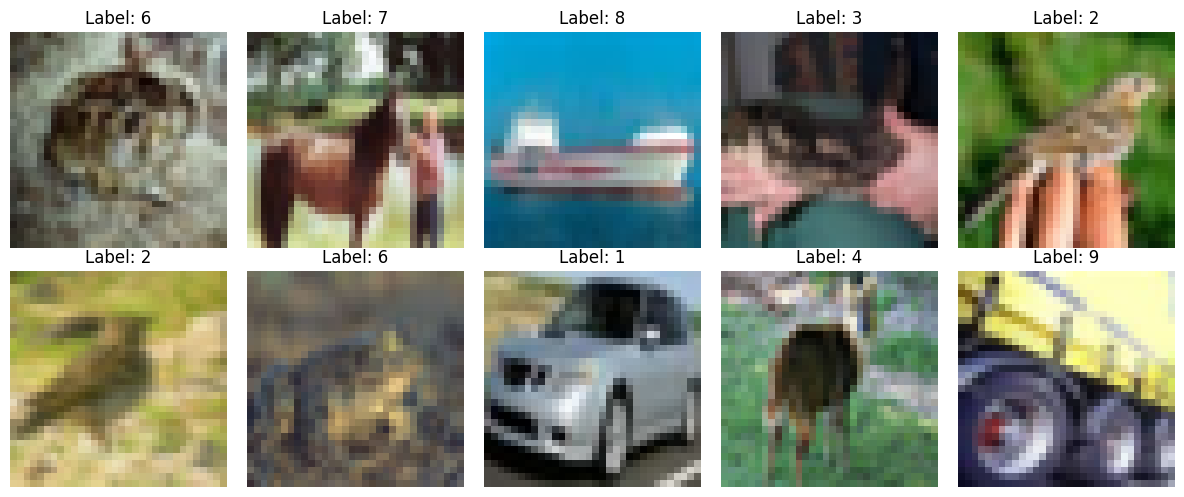

In [3]:
# Show 10 training images in a 2 x 5 subplot.
image_labels = y_train[:10]
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(f"Label: {image_labels[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()


In [4]:
# b. Define a simple CNN architecture.
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 167,562 (654.54 KB)

 Trainable params: 167,562 (654.54 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# c. Train the CNN model.
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
history = model.fit(x_train, y_train, validation_split=0.1,
                    epochs=10, batch_size=64, verbose=2)


Epoch 1/10
563/563 - 15s - 27ms/step - accuracy: 0.4176 - loss: 1.6188 - val_accuracy: 0.5085 - val_loss: 1.3581
Epoch 2/10
563/563 - 15s - 26ms/step - accuracy: 0.5628 - loss: 1.2434 - val_accuracy: 0.5838 - val_loss: 1.1893
Epoch 3/10
563/563 - 14s - 25ms/step - accuracy: 0.6117 - loss: 1.1093 - val_accuracy: 0.6043 - val_loss: 1.1327
Epoch 4/10
563/563 - 14s - 25ms/step - accuracy: 0.6446 - loss: 1.0234 - val_accuracy: 0.6373 - val_loss: 1.0381
Epoch 5/10
563/563 - 15s - 26ms/step - accuracy: 0.6669 - loss: 0.9525 - val_accuracy: 0.6495 - val_loss: 1.0073
Epoch 6/10
563/563 - 15s - 27ms/step - accuracy: 0.6910 - loss: 0.8956 - val_accuracy: 0.6547 - val_loss: 1.0010
Epoch 7/10
563/563 - 15s - 27ms/step - accuracy: 0.7065 - loss: 0.8448 - val_accuracy: 0.6660 - val_loss: 0.9737
Epoch 8/10
563/563 - 15s - 27ms/step - accuracy: 0.7222 - loss: 0.8019 - val_accuracy: 0.6695 - val_loss: 0.9476
Epoch 9/10
563/563 - 15s - 26ms/step - accuracy: 0.7368 - loss: 0.7615 - val_accuracy: 0.6658 - 

Test loss: 0.9761730432510376
Test accuracy: 0.670799970626831


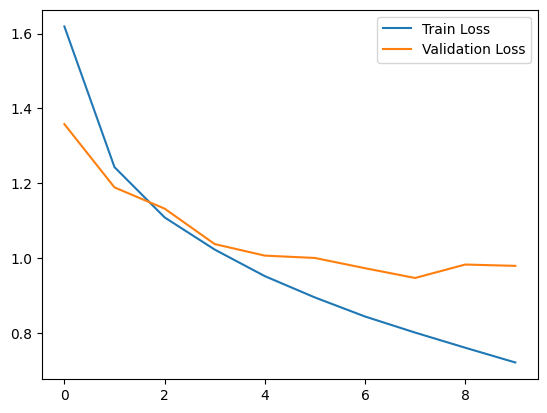

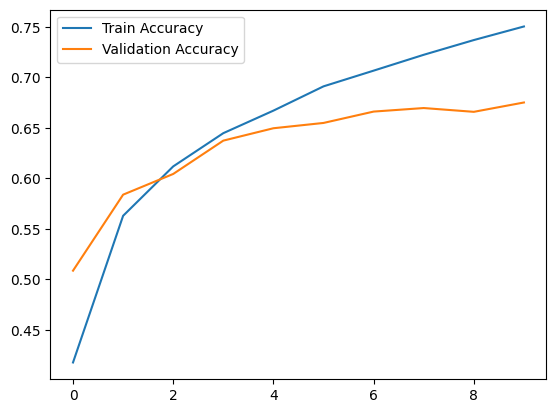

In [6]:
# d. Estimate model performance on test data.
loss, accuracy = model.evaluate(x_test, y_test, verbose=0)
print("Test loss:", loss)
print("Test accuracy:", accuracy)

plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.show()

plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.legend()
plt.show()


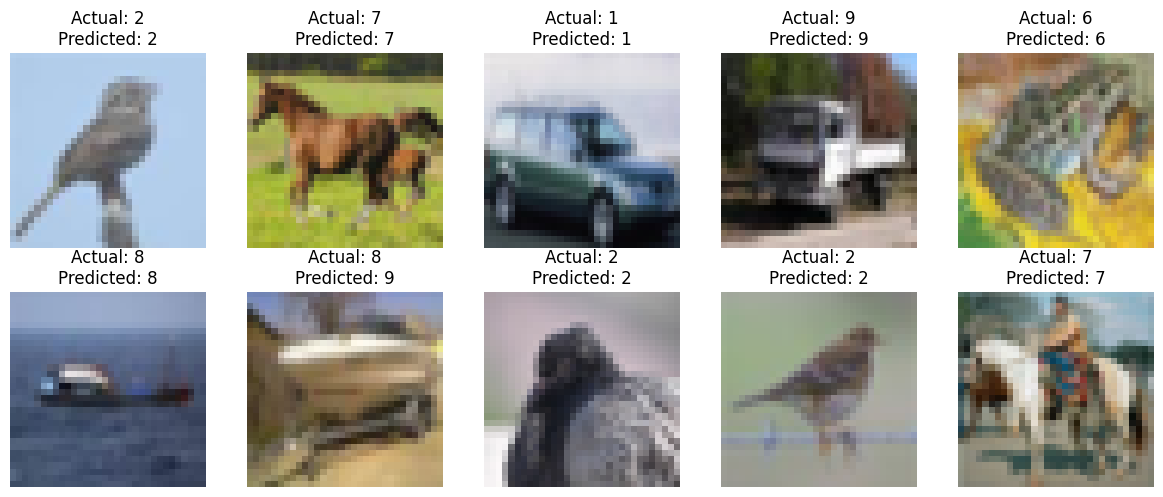

In [7]:
# Show 10 test images with actual and predicted labels after training.
predicted_labels = model.predict(x_test[:10], verbose=0).argmax(axis=1)
actual_labels = y_test[:10]

plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i])
    plt.title(f"Actual: {actual_labels[i]}\nPredicted: {predicted_labels[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()
